# 09｜真实数字分类、卷积归纳偏置与残差连接

这章让网络读出手写数字。每张图只有8×8个灰度像素，我们会用参数量几乎相同的
MLP 和 CNN 训练，查看它们读对了哪些、读错了哪些。

还会把测试图整体右移一个像素。按本章固定的种子和划分，CNN 原图准确率约98%，
右移后降到约58%。一个像素已经占了图像宽度的八分之一，
这个变化将把池化、边界和训练数据覆盖范围的作用显出来。
后半章再给已有特征加一条直接通路，算清残差连接怎样同时改变前向结果和反向梯度。

In [1]:
from support import ROOT, check, show, style

## 1. 读取真实的手写数字


    `load_digits` 将1797张真实手写数字图像随 scikit-learn 一起提供，读取时无需下载。
    每张8×8、像素范围0到16，标签是0到9的类别编号。
    除以已知像素上限16后，输入落在0到1之间；标签保持整数，用于交叉熵。

    `[:,None]` 在样本维之后插入单通道轴，所以打印的输入形状是 `(1797,1,8,8)`，
    每个下标现在都有明确含义：第几张图、哪个通道、哪一行、哪一列。

In [2]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
torch.set_num_threads(1); torch.manual_seed(9); style()
digits = load_digits()
images = torch.tensor(digits.images, dtype=torch.float32)[:, None] / 16.
targets = torch.tensor(digits.target, dtype=torch.long)
print('NCHW:', tuple(images.shape), '标签:', targets.shape)

NCHW: (1797, 1, 8, 8) 标签: torch.Size([1797])


## 2. 同一个划分用于两个模型


    让两个模型回答同一批测试题，比较才有共同的落点。
    这里保留360张测试图，再从其余图中取360张验证图，剩下1077张参与训练。
    `stratify` 按类别分层抽样，使每份数据都含有相近比例的0到9。

    下格打印训练集中各类的数量，可以确认每个数字都有一百多张样本。
    两种模型使用同一划分、各训练18轮；每轮的验证 CE 用来保存参数快照。

In [3]:
indices = np.arange(len(images))
train_valid, test_ids = train_test_split(indices, test_size=.2, random_state=9,
                                         stratify=digits.target)
train_ids, valid_ids = train_test_split(train_valid, test_size=.25, random_state=9,
                                        stratify=digits.target[train_valid])
print('训练/验证/测试:', len(train_ids), len(valid_ids), len(test_ids))
print('训练各类别数:', np.bincount(digits.target[train_ids], minlength=10))

训练/验证/测试: 1077 360 360
训练各类别数: [106 109 107 109 109 109 109 107 104 108]


## 3. 看清模型要识别的笔画


    下图展示12张训练图。同一个数字可以写得很宽、很窄，笔画的灰度也有差别。
    8×8分辨率将很多细节压到一两个像素中，模型需要从这些数值中找到类别线索。

    画图使用 `images[index,0]` 取出二维灰度表；模型计算时仍保留长度1的通道轴。
    记住这些图的清晰程度，后面看错例与位移实验时便有实际参照。

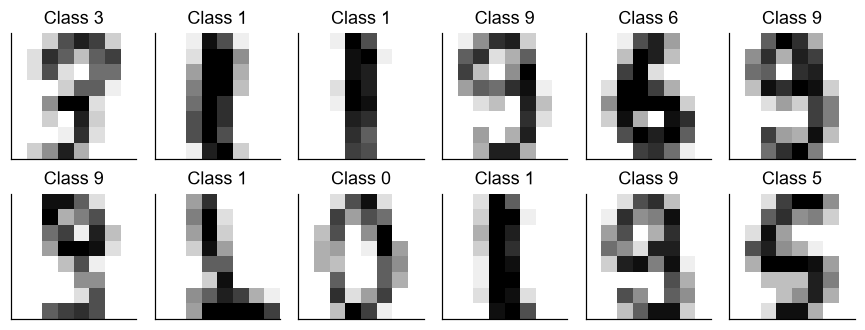

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(8, 3.2))
for ax, index in zip(axes.flat, train_ids[:12]):
    ax.imshow(images[index, 0], cmap='gray_r', vmin=0, vmax=1)
    ax.set(title=f'Class {targets[index].item()}', xticks=[], yticks=[])
fig.tight_layout(); show(fig)

### 练习 9.1：给灰度图加入通道维

输入张量形状 `(5,8,8)`，用 `[:,None,:,:]` 变成 NCHW，返回新形状。

In [5]:
ex_t91_result = None

In [6]:
# 填写上一格后，运行检查。
check('NCHW形状', ex_t91_result, [5, 1, 8, 8])

待填写：NCHW形状


<details>
<summary>提示</summary>

新插入的维度位于样本数之后，长度是1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t91_images = torch.zeros(5, 8, 8)
ex_t91_result = list(ex_t91_images[:, None, :, :].shape)
```

</details>

## 4. MLP 基线：每个像素是一个输入特征


    把64个像素逐行排成一个向量，就能沿用上一章的 MLP。
    `Flatten` 把 `(B,1,8,8)` 变成 `(B,64)`，隐藏层用26个响应，最后输出10个类别分数。
    每个隐藏单元都给64个像素各分配一个权重，可以直接使用整张图的信息。
    参数量为
    $64\times26+26+26\times10+10=1960$。

In [7]:
class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden = nn.Linear(64, 26)
        self.output = nn.Linear(26, 10)
    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.hidden(x))
        return self.output(x)

## 5. CNN：在各处使用同一组局部规则


    CNN 将上一章的窗口计算用于每张数字图。第一层的每份3×3核只读取一小块笔画，
    在各位置重复使用；第二层读取第一层的局部响应，继续组合特征。
    两层3×3卷积都补零1，保持8×8空间尺寸；每层输出8个通道。
    2×2最大池化、步幅2后变成4×4。展平得到 $8\times4\times4=128$ 个特征，
    最后线性层输出10个 logits。总参数量1954，与 MLP 的1960接近。
    这些参数被安排成局部连接、共享核与池化，规定了模型怎样组合图像信息。
    这种由结构预先给定的偏好称为归纳偏置。训练会学习核的具体数值，
    而“同一核用于各处”这条结构关系在训练前已经确定。

In [8]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)
        self.conv2 = nn.Conv2d(8, 8, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.output = nn.Linear(8 * 4 * 4, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        return self.output(x.flatten(start_dim=1))

## 6. 逐层验证形状


    用四张图穿过每一层，打印它们的形状。卷积把通道数改为8，补零让空间尺寸保持8×8；
    池化后变成4×4，展平就是128项。最后的 Linear 因而接收128项，输出10项。

    `flatten(start_dim=1)` 从通道轴开始合并，保留最前面的批维。
    输出末尾的 `(4,10)` 表示四份样本各有十个分数，正好接上类别编号组成的目标。

In [9]:
torch.manual_seed(9)
models = {'MLP': DigitMLP(), 'CNN': DigitCNN()}
shape_net = models['CNN']
shape_x = images[train_ids[:4]]
for name, layer in [('conv1', shape_net.conv1), ('relu1', nn.ReLU()),
                     ('conv2', shape_net.conv2), ('relu2', nn.ReLU()),
                     ('pool', shape_net.pool), ('flatten', nn.Flatten()),
                     ('output', shape_net.output)]:
    shape_x = layer(shape_x)
    print(name, tuple(shape_x.shape))
print('参数量:', {name: sum(p.numel() for p in net.parameters()) for name, net in models.items()})

conv1 (4, 8, 8, 8)
relu1 (4, 8, 8, 8)
conv2 (4, 8, 8, 8)
relu2 (4, 8, 8, 8)
pool (4, 8, 4, 4)
flatten (4, 128)
output (4, 10)
参数量: {'MLP': 1960, 'CNN': 1954}


### 练习 9.2：卷积与池化的组合形状

输入 `(4,3,12,12)`，先 Conv2d(3,5,3,padding=1)，再 MaxPool2d(2)，返回输出形状。

In [10]:
ex_t92_result = None

In [11]:
# 填写上一格后，运行检查。
check('组合输出形状', ex_t92_result, [4, 5, 6, 6])

待填写：组合输出形状


<details>
<summary>提示</summary>

卷积保持空间尺寸，池化把高宽各减半。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t92_net = nn.Sequential(nn.Conv2d(3, 5, 3, padding=1), nn.MaxPool2d(2))
ex_t92_result = list(ex_t92_net(torch.zeros(4, 3, 12, 12)).shape)
```

</details>

## 7. 训练数据如何组成 batch


    一批64张图的输入是 `(64,1,8,8)`，目标是64个类别编号，模型输出 `(64,10)`。
    `TensorDataset` 将每张图与同一下标的标签配对，DataLoader 负责打乱并分批。

    两次训练各自调用 `make_loader()`，都从种子9开始取样，因此各轮样本顺序也相同。
    下格实际取出一批并计算输出，可以沿着这三个形状追踪样本维。

In [12]:
def make_loader():
    dataset = TensorDataset(images[train_ids], targets[train_ids])
    return DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(9))
example_x, example_y = next(iter(make_loader()))
print('batch输入:', tuple(example_x.shape), '目标:', tuple(example_y.shape))
print('模型输出:', tuple(models['CNN'](example_x).shape))

batch输入: (64, 1, 8, 8) 目标: (64,)
模型输出: (64, 10)


## 8. 用同一份训练函数更新两个模型


    循环不需要知道传进来的是 MLP 还是 CNN：两者都接收这一批图像，返回十类 logits。
    每一批的交叉熵反传到各自参数，Adam 完成更新。
    `total` 收集这一轮的损失和，再除以1077得到训练集平均值。

    一轮结束后，模型在360张验证图上给出 CE 和准确率。
    验证 CE 降低时保存当前参数，结束后恢复这份参数；records 则保留每轮的三项指标。

In [13]:
def train_digits(net, epochs=18):
    loader = make_loader()
    optimizer = torch.optim.Adam(net.parameters(), lr=.01)
    records, best_value, best_state = [], float('inf'), None
    for epoch in range(epochs):
        net.train(); total = 0.
        for inputs, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(net(inputs), labels)
            loss.backward(); optimizer.step()
            total += loss.item() * len(inputs)
        net.eval()
        with torch.no_grad():
            z = net(images[valid_ids])
            valid_loss = F.cross_entropy(z, targets[valid_ids]).item()
            valid_acc = (z.argmax(1) == targets[valid_ids]).float().mean().item()
        records.append((total / len(train_ids), valid_loss, valid_acc))
        if valid_loss < best_value:
            best_value = valid_loss
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return np.asarray(records)

### 练习 9.3：最大池化把梯度送到哪里

输入2×2表 `[[1,4],[2,3]]`，最大池化得到一个数，再对输出之和反传，返回输入梯度。

In [14]:
ex_t93_result = None

In [15]:
# 填写上一格后，运行检查。
check('最大池化输入梯度', ex_t93_result, [[0., 1.], [0., 0.]])

待填写：最大池化输入梯度


<details>
<summary>提示</summary>

只有最大元素4影响这个窗口的最大值，它收到单位梯度。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t93_x = torch.tensor([[[[1., 4.], [2., 3.]]]], requires_grad=True)
F.max_pool2d(ex_t93_x, 2).sum().backward()
ex_t93_result = ex_t93_x.grad[0, 0].clone()
```

</details>

## 9. 两个模型在留出数字上的表现


    在这份划分上，MLP 测试准确率约96.1%，CNN 约98.1%。
    这两个小模型分别用1960、1954个参数，以同样批大小训练18轮，
    卷积中的同一参数仍会在多个位置参与运算。

    打印的“验证最高准确率”取自训练过程，测试准确率则使用验证 CE 最低时保存的参数。
    准确率与 CE 关注的数值不同：前者只数类别对错，后者还取决于正确类概率的大小。

In [16]:
histories = {name: train_digits(net) for name, net in models.items()}
test_predictions = {}
for name, net in models.items():
    net.eval()
    with torch.no_grad():
        predictions = net(images[test_ids]).argmax(1)
    test_predictions[name] = predictions
    accuracy = (predictions == targets[test_ids]).float().mean().item()
    print(name, '参数:', sum(p.numel() for p in net.parameters()),
          '验证最高准确率:', round(histories[name][:, 2].max(), 4),
          '测试准确率:', round(accuracy, 4))

MLP 参数: 1960 验证最高准确率: 0.975 测试准确率: 0.9611
CNN 参数: 1954 验证最高准确率: 0.9972 测试准确率: 0.9806


## 10. 曲线和错例提供不同的信息


    曲线把18轮训练展开在同一横轴上。左图记录训练 CE，右图记录验证准确率，
    可以沿同一轮的横坐标，对照训练误差的下降与留出图正确比例的变化。

    随后的错例图按测试集顺序取 CNN 的前几个错误，标题 T/P 为真实类别与预测类别。
    对一张错图，可以具体指出哪段笔画模糊、闭合或偏移，并与图中的预测数字比较。
    一个总准确率没有保留这些图像细节。

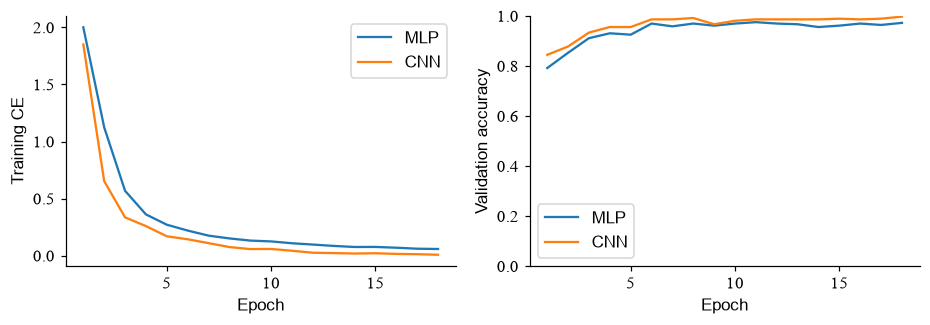

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1))
for name, records in histories.items():
    axes[0].plot(np.arange(1, len(records) + 1), records[:, 0], label=name)
    axes[1].plot(np.arange(1, len(records) + 1), records[:, 2], label=name)
axes[0].set(xlabel='Epoch', ylabel='Training CE'); axes[0].legend()
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy', ylim=(0, 1)); axes[1].legend()
fig.tight_layout(); show(fig)

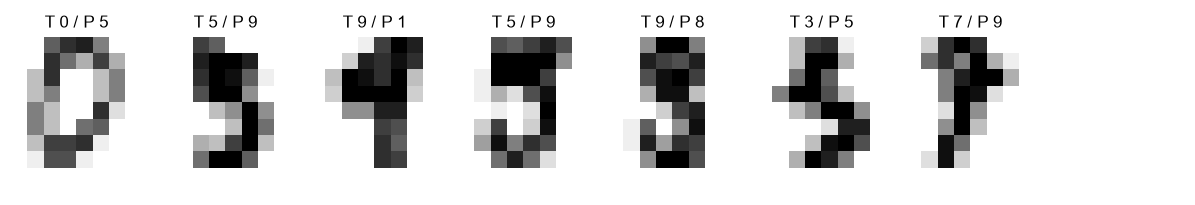

In [18]:
wrong = torch.where(test_predictions['CNN'] != targets[test_ids])[0][:8]
fig, axes = plt.subplots(1, 8, figsize=(11, 2))
for ax in axes:
    ax.axis('off')
for ax, local_index in zip(axes, wrong):
    index = test_ids[local_index.item()]
    ax.imshow(images[index, 0], cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'T {targets[index].item()} / P {test_predictions["CNN"][local_index].item()}', fontsize=11)
fig.tight_layout(); show(fig)

## 11. 右移一个像素后，哪些东西改变了


    2×2最大池化只保留窗口内的最大响应。下格把峰值2在同一个窗口里换位置，
    两次输出都是2；跨过池化窗口边界时，这个结果就可能改变。

    接着将360张测试图整体右移一像素，左边补0、最右列移出图像。
    MLP 与 CNN 的准确率都会明显下降。除了像素位置改变，
    池化窗口分组、图像边缘与展平后的特征位置也随之改变。
    本次训练使用的原始图像并未覆盖这整组平移后的输入，
    因而“局部共享规则”在这里带来的稳定程度，要由实际预测结果回答。

In [19]:
peak_a = torch.tensor([[[[0., 2.], [0., 0.]]]])
peak_b = torch.tensor([[[[0., 0.], [2., 0.]]]])
print('移动前后池化:', F.max_pool2d(peak_a, 2).item(), F.max_pool2d(peak_b, 2).item())
shifted_test = torch.zeros_like(images[test_ids])
shifted_test[:, :, :, 1:] = images[test_ids][:, :, :, :-1]
for name, net in models.items():
    with torch.no_grad():
        shifted_acc = (net(shifted_test).argmax(1) == targets[test_ids]).float().mean().item()
    print(name, '右移1像素测试准确率:', round(shifted_acc, 4))

移动前后池化: 2.0 2.0
MLP 右移1像素测试准确率: 0.475
CNN 右移1像素测试准确率: 0.575


### 练习 9.4：平移时边界怎样处理

对一行像素 `[1,2,3,4]` 实现右移一格、左边补0，返回新行。不要让最后一个像素绕回左边。

In [20]:
ex_t94_result = None

In [21]:
# 填写上一格后，运行检查。
check('补零平移', ex_t94_result, [0., 1., 2., 3.])

待填写：补零平移


<details>
<summary>提示</summary>

先建立全0张量，再令新行的1:等于旧行的:-1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t94_row = torch.tensor([1., 2., 3., 4.])
ex_t94_result = torch.zeros_like(ex_t94_row)
ex_t94_result[1:] = ex_t94_row[:-1]
```

</details>

## 12. 让新增的一层保留已有输入


    假设前面已经算出一份有用的特征 x，还想通过更多层改进它。
    用 $y=x+F(x)$ 时，新增分支只需给出要加到原特征上的修正；
    当 F=0，整个块便输出原来的 x。这就是残差连接的直接用途。

    输入经过直接路径和 F 分支两次到达 y。对输入求导：
    $$\frac{dy}{dx}=1+F'(x),\qquad
      \frac{dL}{dx}=\frac{dL}{dy}\bigl(1+F'(x)\bigr).$$
    下格 $F(x)=\tanh(0.2x)$、x=0.5，分支导数约0.198，直接路径导数为1，
    所以总导数约1.198。这个1在 F 分支导数较小时仍存在；
    两路贡献带着正负号相加，若某处 $F'(x)=-1$，总和也会为0。

In [22]:
residual_x = torch.tensor(.5, dtype=torch.float64, requires_grad=True)
residual_w = torch.tensor(.2, dtype=torch.float64)
branch = torch.tanh(residual_w * residual_x)
residual_y = residual_x + branch
residual_y.backward()
expected = 1 + residual_w * (1 - branch.detach().square())
print('直接路径:', 1., '分支路径:', (expected - 1).item(), '总梯度:', residual_x.grad.item())
check('标量残差导数', residual_x.grad, expected)

直接路径: 1.0 分支路径: 0.198013258169488 总梯度: 1.198013258169488
通过：标量残差导数


## 13. 向量情形：I+J 的每个维度


    图像特征含有许多坐标，直接路径将每个输入坐标复制到输出的同一坐标，
    因此它的导数是单位矩阵 I。采用列向量 $x,y\in\mathbb R^d$，$F:\mathbb R^d\to\mathbb R^d$。
    雅可比矩阵 $J_F$ 的第 $(i,j)$ 项为 $\partial F_i/\partial x_j$，
    所以 $J_y=I+J_F$。若上游梯度为列向量 $g=\nabla_yL$，
    $$\nabla_xL=(I+J_F)^\top g=g+J_F^\top g.$$
    转置来自反向收集：一个输入坐标需要收齐它对所有输出坐标的影响。
    下格令 $F(x)=Wx$，上游梯度 $g=[2,-1]$；分支回传 $W^\top g=[0,-0.7]$，
    再加直接路径的 `[2,-1]`，得到输入梯度 `[2,-1.7]`。

In [23]:
vector_x = torch.tensor([1., 2.], dtype=torch.float64, requires_grad=True)
matrix_w = torch.tensor([[.2, -.3], [.4, .1]], dtype=torch.float64)
upstream = torch.tensor([2., -1.], dtype=torch.float64)
vector_y = vector_x + matrix_w @ vector_x
vector_loss = upstream @ vector_y
vector_loss.backward()
print('直接贡献:', upstream, '分支贡献:', matrix_w.T @ upstream)
check('向量残差回传', vector_x.grad, upstream + matrix_w.T @ upstream)

直接贡献: tensor([ 2., -1.], dtype=torch.float64) 分支贡献: tensor([ 0.0000, -0.7000], dtype=torch.float64)
通过：向量残差回传


### 练习 9.5：把两路梯度相加

$F(x)=Wx$，$W=[[0,2],[1,0]]$，上游梯度 $g=[3,4]$。手算残差输出 $x+Wx$ 对输入的梯度。

In [24]:
ex_t95_result = None

In [25]:
# 填写上一格后，运行检查。
check('残差两路回传', ex_t95_result, [7., 10.])

待填写：残差两路回传


<details>
<summary>提示</summary>

列向量约定下是 $g+W^\top g$。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t95_W = torch.tensor([[0., 2.], [1., 0.]])
ex_t95_g = torch.tensor([3., 4.])
ex_t95_result = ex_t95_g + ex_t95_W.T @ ex_t95_g
```

</details>

## 14. 写出同形状的卷积残差块


    将标量分支换成两层卷积，就能对整份图像特征应用同一结构。
    输入 `(B,C,H,W)` 经过两层3×3卷积，步幅1、补零1使高宽保持相同，
    输入输出通道数也相同，因此 x 与 branch 可以逐元素相加。

    下面的 `return x + branch` 正是 $x+F(x)$。中间的 ReLU 属于 F 的内部计算，
    其局部导数会包含在 $J_F$ 中。把分支参数全部设为0的练习，将直接核验保留输入及其梯度的效果。

In [26]:
class SmallResidual(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1)
    def forward(self, x):
        branch = self.conv2(F.relu(self.conv1(x)))
        return x + branch
block = SmallResidual(8)
print('残差块输入输出:', (4, 8, 8, 8), tuple(block(torch.zeros(4, 8, 8, 8)).shape))

残差块输入输出: (4, 8, 8, 8) (4, 8, 8, 8)


## 15. 改变通道或尺寸时补上投影


    如果主分支把8个通道改成16个，并将8×8缩成4×4，原输入就少了通道、多了空间位置，
    无法与分支逐格相加。捷径用1×1卷积混合通道，步幅2同时缩小空间尺寸，
    两路便都成为 `(B,16,4,4)`。

    这个块写作 $y=P(x)+F(x)$，P 是刚才的投影。
    输入梯度随之成为 $J_P^\top g+J_F^\top g$。直接复制产生的 I，
    在这里换成了投影计算的雅可比；两条路径仍在同一个输入处相加。

In [27]:
projection = nn.Conv2d(8, 16, kernel_size=1, stride=2)
down_branch = nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1)
demo_features = torch.randn(4, 8, 8, 8)
projected = projection(demo_features)
branch_features = down_branch(demo_features)
print('捷径与分支:', tuple(projected.shape), tuple(branch_features.shape))
print('相加后:', tuple((projected + branch_features).shape))

捷径与分支: (4, 16, 4, 4) (4, 16, 4, 4)


相加后: (4, 16, 4, 4)


[打开残差交互实验](../interactive/index.html#residual)：选择“F=0，保留输入”，
逐步观察输出与输入梯度；再选择“两路导数抵消”，把两份带符号的贡献亲手相加。
最后切到相加后接 ReLU，观察加和为负时，后激活怎样同时改变两条反向路径。

### 练习 9.6：零分支给出的可核验证据

新建 SmallResidual(2)，把分支的所有参数设成0。输入随机 `(1,2,3,3)`，计算输出之和的输入梯度。

In [28]:
ex_t96_result = None

In [29]:
# 填写上一格后，运行检查。
check('零分支的恒等梯度', ex_t96_result, torch.ones(1, 2, 3, 3))

待填写：零分支的恒等梯度


<details>
<summary>提示</summary>

在 `no_grad` 中把参数 `zero_()`；分支为0，直接路径导数仍为1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t96_block = SmallResidual(2)
with torch.no_grad():
    for ex_t96_p in ex_t96_block.parameters():
        ex_t96_p.zero_()
ex_t96_x = torch.randn(1, 2, 3, 3, requires_grad=True)
ex_t96_block(ex_t96_x).sum().backward()
ex_t96_result = ex_t96_x.grad.clone()
```

</details>

## 16. 从这个小实验走向 NTU 的图像作业

本地 [HW06.ipynb](../../NTU_HYLee/GenAI_ML/hw/HW06.ipynb) 分类 MyGO/Ave Mujica 的10个人物，
原图是150×150×3，作业预处理调整为128×128×3，图像比本章大得多，也增加了颜色通道。
它仍然经历“读取图像与标签→NCHW batch→类别 logits→交叉熵”这条数据流。
其中输入张量的通道数改为3，输出仍有10类，卷积层与 Linear 层的维度要跟着数据变化。

可在作业中沿一张图追到预测结果，特别看清 resize、标签映射和增强发生在哪一步。
本章右移实验已经给出一个参照：增强怎样改变输入分布、增强后类别是否仍成立，
都会影响模型收到的训练信息。预训练模型又提供了已有特征这一新起点，
理解本章各层参数怎样更新后，就能继续追踪它的哪些层会被微调。

## 带着问题读原文

[He 等：Deep Residual Learning for Image Recognition（2015）](https://arxiv.org/abs/1512.03385)

对照论文的 basic block，标出卷积、激活、相加和捷径投影。如果相加之后再接 ReLU，把本课的输入梯度公式补上这个激活的雅可比，写清它乘在哪一侧。

**单变量实验：**保持数据、划分、轮数不变，只把 CNN 的 MaxPool2d(2) 换成 AvgPool2d(2)。比较验证曲线、原测试准确率、右移测试准确率；从这三项证据判断池化方式的影响。